# 第 01 关：分散化、共同风险与 CAPM

**本关要回答的问题：** 同样是"有风险"，为什么市场只为其中一部分风险付报酬？

先讲直觉。投资者可以同时持有很多资产。一只股票自己特有的涨跌（比如某家药企的新药试验失败），放进大组合后会被其他股票的涨跌抵消，这类风险叫**可分散风险**，也叫特质风险。全市场一起下跌（比如经济衰退）却无法靠多买几只股票躲开，这类风险叫**系统性风险**，也叫共同风险。既然可分散风险能免费消除，市场就没有理由为它付补偿；只有系统性风险才需要补偿。

本关分三步把这个直觉变成数字：
1. 用一个可控的模拟，看分散化能消除多少风险、消除不了多少；
2. 用真实行业数据，看风险和平均收益之间有哪些组合方式可选；
3. 估计衡量系统性风险的指标：市场 β。

### 需要的概念
- **标准差（波动率）σ**：收益围绕平均值波动的幅度，衡量一项资产的总风险。
- **相关系数 ρ**：两个资产同涨同跌的程度，介于 −1 和 1 之间。
- **协方差**：$\operatorname{Cov}(X,Y)=\rho\,\sigma_X\sigma_Y$，同时反映相关程度和各自的波动幅度。
- **Markowitz（1952）组合理论**：给定各资产的预期收益和协方差，投资者在"平均收益高"和"波动小"之间权衡来选组合。关键洞见是：组合的风险取决于资产之间的协方差，而不只是各资产自己的波动。
- **CAPM（Capital Asset Pricing Model，资本资产定价模型；Sharpe 1964）**：在 Markowitz 的基础上假设所有投资者都这样选组合、对未来的看法相同、能以无风险利率自由借贷，并要求市场处于**均衡**（价格调整到每项资产都恰好有人愿意持有）。由此推出，所有人持有的风险资产组合就是**市场组合**（全部风险资产按市值加权），并且

$$
E(R_i-R_f)=\beta_i\,E(R_M-R_f),\qquad \beta_i=\frac{\operatorname{Cov}(R_i,R_M)}{\operatorname{Var}(R_M)}.
$$

左边是资产 $i$ 的**预期超额收益**（预期收益减无风险利率 $R_f$）；$E(R_M-R_f)$ 是市场组合的预期超额收益，称为**市场风险溢价**。**β** 衡量资产随市场共同变动的程度：β = 1.5 表示市场多涨 1%，这项资产平均多涨 1.5%。CAPM 的结论是：**预期超额收益只由 β 决定**，与资产自身的总波动无关。

这个等式是模型对数据做出的可检验预测。本关先学会计算 β，第 03 关再正式检验这个预测。

参考：[Markowitz 1952](https://doi.org/10.1111/j.1540-6261.1952.tb01525.x)、[Sharpe 1964](https://doi.org/10.1111/j.1540-6261.1964.tb02865.x)。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/course.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from course import (load_raw, load_returns, raw_path, catalog, manifest, style,
                    build_ff3, build_ff5, heatmap25, save_table, paper_note)
from analysis import fit_models, grs_test, model_summary
style()
print('项目目录：', ROOT)

项目目录： E:\Eth data\asset_pricing_quest


## 1. 一个可控的分散化实验
设想有 $n$ 个资产，每个的年波动率都是 $\sigma=20\%$，任意两个之间的相关系数都是 $\rho=0.2$，每个资产投入 $1/n$ 的资金。这些数字是为了看清机制而设定的。

这个等权组合的方差可以直接算出来：

$$
\sigma_p^2=\underbrace{\frac{\sigma^2}{n}}_{\text{各资产自己的波动}}+\underbrace{\Big(1-\frac1n\Big)\rho\,\sigma^2}_{\text{资产之间的共同波动}}
=\sigma^2\Big(\rho+\frac{1-\rho}{n}\Big).
$$

第一项随 $n$ 增大趋于 0，这就是可分散风险。第二项来自资产之间的共同波动，$n$ 再大也降不到 $\rho\sigma^2$ 以下，这就是系统性风险。所以组合波动率有一个下限：$\sigma\sqrt{\rho}=20\%\times\sqrt{0.2}\approx 8.9\%$。

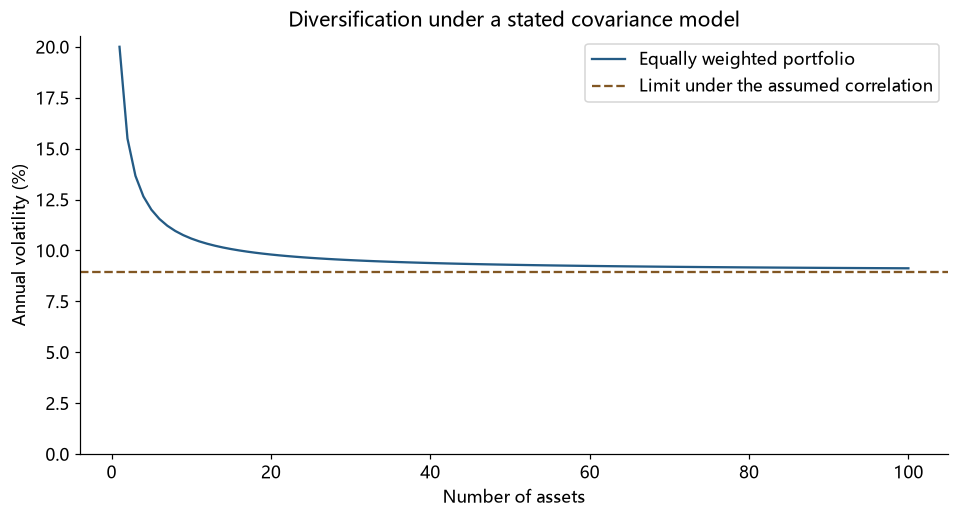

In [2]:
n = np.arange(1, 101)
sigma, rho = .20, .20
portfolio_vol = sigma * np.sqrt(rho + (1-rho)/n)
fig, ax = plt.subplots(layout='constrained')
ax.plot(n, portfolio_vol*100, color='#245b85', label='Equally weighted portfolio')
ax.axhline(sigma*np.sqrt(rho)*100, color='#825723', linestyle='--', label='Limit under the assumed correlation')
ax.set(xlabel='Number of assets', ylabel='Annual volatility (%)', title='Diversification under a stated covariance model')
ax.set_ylim(bottom=0); ax.legend(); plt.show()

**怎么读这张图：** 蓝线是组合的年波动率。它随资产数增加迅速下降，到二三十个资产之后几乎不再下降；虚线是 8.9% 的下限。前几个资产带来的分散化效果最大。相关系数越高，下限越高，分散化能消除的风险就越少。

这就是 CAPM 只为系统性风险付补偿的原因：可分散的那部分，投资者自己就能免费消除。至于真实市场中的共同风险能否全部由"市场组合"这一个方向来代表，要由后面几关的检验回答。

## 2. 用真实行业收益看风险与收益的取舍
现在换成真实数据。取 French 30 个行业组合中的前 5 个（Food 食品、Beer 酒类、Smoke 烟草、Games 娱乐休闲、Books 印刷出版），用 1963-07 至 1991-12 的月度数据估计每个行业的平均收益 $\mu$ 和协方差矩阵 $\Sigma$。

然后随机生成 4000 组投资权重 $w$：每组权重都不小于 0（只买入、不卖空）并且加起来等于 1。Dirichlet 分布正好能均匀地生成这样的权重。对每组权重计算组合的平均收益 $w'\mu$ 和标准差 $\sqrt{w'\Sigma w}$，在图上画成一个点。

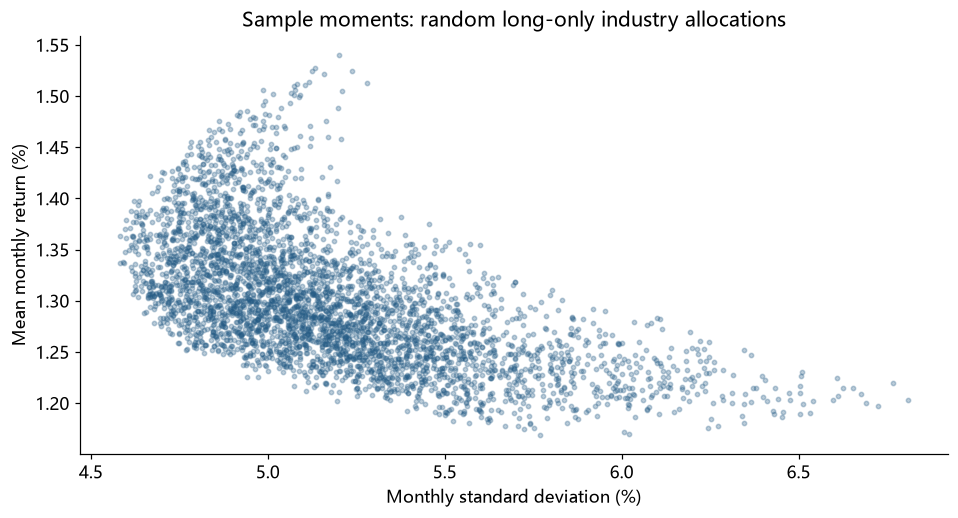

,mean_pct_month,sd_pct_month
Food,1.2755,4.7108
Beer,1.3149,5.5842
Smoke,1.5784,5.4192
Games,1.1753,7.4035
Books,1.1533,5.9675


In [3]:
industry = load_returns('industry30', '1963-07', '1991-12').iloc[:, :5]   # 前 5 个行业
mu, cov = industry.mean().to_numpy(), industry.cov().to_numpy()           # 月均收益向量、协方差矩阵
rng = np.random.default_rng(1964)                                          # 固定随机种子，结果可复现
weights = rng.dirichlet(np.ones(5), 4000)      # 4000 行，每行 5 个非负权重，和为 1
mean_return = weights @ mu                     # 每组权重的组合平均收益 w'μ
risk = np.sqrt(np.einsum('ij,jk,ik->i', weights, cov, weights))   # 每组权重的组合标准差 sqrt(w'Σw)
fig, ax = plt.subplots(layout='constrained')
ax.scatter(risk*100, mean_return*100, s=8, alpha=.30, color='#245b85')
ax.set(xlabel='Monthly standard deviation (%)', ylabel='Mean monthly return (%)', title='Sample moments: random long-only industry allocations')
plt.show()
display(pd.DataFrame({'mean_pct_month':industry.mean()*100,'sd_pct_month':industry.std()*100}))

**怎么读：** 每个点是一种配置。点云的左上边缘是"同样风险下平均收益最高"的组合，它就是**有效前沿**的直观形状（这里只有 5 个行业、不允许卖空，所以是简化版本）。下表给出 5 个行业各自的月均收益（`mean_pct_month`）和月度标准差（`sd_pct_month`），单位都是 %：烟草的平均收益最高，娱乐休闲的波动最大。

这里的均值和协方差是用整段历史事后算出来的，1963 年的投资者并不知道。均值的估计误差尤其大，这是实际做组合配置时最难处理的问题之一。

## 3. 从共同变动估计市场 β
β 的定义是 $\beta_i=\operatorname{Cov}(R^e_i,R^e_M)/\operatorname{Var}(R^e_M)$，其中 $R^e$ 表示超额收益。有两种等价的算法：
1. **按定义直接算**：样本协方差除以样本方差；
2. **回归**：把行业超额收益对市场超额收益做带截距的**普通最小二乘（OLS）**回归

$$R^e_{i,t}=\alpha_i+\beta_i R^e_{M,t}+\varepsilon_{i,t},$$

斜率就是 β。截距 **α** 是资产平均超额收益中市场解释不了的部分：如果 CAPM 成立，α 应该等于 0。$\varepsilon_{i,t}$ 是每个月的残差。

下面对 5 个行业分别用两种方法算 β，并报告 α。`fit_models` 是课程的回归函数，定义在 `src/analysis.py`。

In [4]:
ff = load_returns('ff3','1963-07','1991-12')
y = industry.sub(ff['RF'],axis=0)                                           # 行业超额收益
beta_cov = y.apply(lambda x: x.cov(ff['Mkt-RF']) / ff['Mkt-RF'].var())    # 方法 1：协方差 / 方差
estimates, _ = fit_models(y,ff[['Mkt-RF']])                                 # 方法 2：带截距的 OLS 回归
compare = pd.DataFrame({'covariance_beta':beta_cov,'ols_beta':estimates['beta_Mkt-RF'],'alpha_pct_month':estimates['alpha_pct_month']})
display(compare)
assert np.allclose(compare.covariance_beta, compare.ols_beta)               # 两种方法必须相同
save_table(compare,'01_industry_beta')

,covariance_beta,ols_beta,alpha_pct_month
Food,0.8715,0.8715,0.3646
Beer,0.9574,0.9574,0.3687
Smoke,0.8010,0.8010,0.6964
Games,1.3520,1.3520,0.0670
Books,1.1318,1.1318,0.1355


WindowsPath('E:/Eth data/asset_pricing_quest/results/01_industry_beta.csv')

**怎么读：** `covariance_beta` 和 `ols_beta` 完全相同，说明回归斜率就是协方差比率。`alpha_pct_month` 是截距 α，单位 %/月。娱乐休闲的 β 约 1.35：市场每多涨 1%，它平均多涨 1.35%；烟草的 β 约 0.80，跟随市场的程度较低。

值得注意的是：烟草的 β 最低，α 却最高（约 0.70%/月）。按 CAPM，它应该获得较低的平均收益，实际却是 5 个行业中最高的。这提示 β 也许解释不了全部的平均收益差异。α 是否可靠地不为零，还要考虑估计误差，这是第 03 关的任务。

## Boss 作答区

选两个行业，描述它们的波动率和 β。要解释它们平均收益的差异，你还需要哪些证据？

**我的回答：**

（由你填写；本课程未预填答案。）